# Modul 8 — Perbandingan Metode Deteksi Anomali
Data pabrik tidak memberi label "ini anomali". Maka pertanyaan yang jujur adalah dua:
1. **Seberapa baik tiap metode menemukan anomali yang kita tahu jawabannya?** (uji pada data dengan anomali yang *disuntikkan*)
2. **Apa yang ditemukan tiap metode pada data nyata, dan apakah mereka sepakat?**

Lima metode: **z-score robust** (univariat), **Elliptic Envelope/MCD** (jarak Mahalanobis robust), **Isolation Forest**, **Local Outlier Factor (LOF)**, dan **residu regresi** (menurut pengetahuan proses).

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import roc_auc_score, average_precision_score

pd.set_option("display.width", 150, "display.max_columns", 30)
XLSX = "Smelter_Data_Lanjutan.xlsx"
try:
    from google.colab import files
    if not os.path.exists(XLSX): files.upload()
except ImportError:
    pass
S = pd.read_excel(XLSX, sheet_name=None)
d = S["Data_Harian"].merge(S["Proses_Harian"], on="Tanggal"); d["Tanggal"] = pd.to_datetime(d["Tanggal"])
d = d.sort_values("Tanggal").reset_index(drop=True)
FITUR = ["Konsentrat_Masuk_DMT", "Cu_Grade_Persen", "Jam_Downtime", "Recovery_Persen", "Energi_per_t_Katoda_MWh",
         "Suhu_FSF_C", "O2_Enrichment_Persen", "Cu_Slag_Persen", "Matte_Grade_Persen"]
X0 = d[FITUR].copy()
print(X0.shape)

Saving Smelter_Data_Lanjutan.xlsx to Smelter_Data_Lanjutan.xlsx
(273, 9)


## 1. Lima detektor dengan antarmuka yang sama
**Pra-pemrosesan itu penting.** `Jam_Downtime` bernilai 0 pada sekitar 75% hari, sehingga skala robust (MAD) = 0 dan fitur ini meledak jika tidak ditangani. Fungsi `prep` meredam skewness dengan `log1p` dan memakai skala cadangan.
Setiap fungsi menerima tabel fitur dan mengembalikan **skor anomali** (makin besar makin ganjil). Dengan skor, kita bisa menilai tanpa memilih ambang terlebih dahulu.

In [ ]:
def prep(X):
    """Pra-pemrosesan bersama. Jam_Downtime bernilai 0 pada ~75% hari (zero-inflated): MAD-nya 0 sehingga skala robust biasa
    meledak. Solusi: log1p dulu, lalu pakai skala robust (MAD) bila > 0, jika tidak simpangan baku."""
    Z = X.copy(); Z["Jam_Downtime"] = np.log1p(Z["Jam_Downtime"])
    med = Z.median(); mad = 1.4826 * (Z - med).abs().median(); sd = Z.std()
    return (Z - med) / mad.where(mad > 0, sd)

def skor_z(X):
    return prep(X).abs().max(axis=1).values                 # penyimpangan terbesar pada satu fitur

def skor_mcd(X):
    Xs = prep(X).values
    m = EllipticEnvelope(contamination=0.05, support_fraction=0.8, random_state=0).fit(Xs)
    return -m.score_samples(Xs)

def skor_iforest(X):
    Xs = prep(X).values
    m = IsolationForest(n_estimators=300, contamination="auto", random_state=0).fit(Xs)
    return -m.score_samples(Xs)

def skor_lof(X):
    Xs = prep(X).values
    m = LocalOutlierFactor(n_neighbors=20, novelty=False).fit(Xs)
    return -m.negative_outlier_factor_

def skor_residu(X):
    """Prediksi tiap variabel kunci (energi/t, recovery, suhu, O2) dari fitur lain secara linear; skor = residu terbesar yang dibakukan."""
    out = []
    for target in ["Energi_per_t_Katoda_MWh", "Recovery_Persen", "Suhu_FSF_C", "O2_Enrichment_Persen"]:
        P = np.column_stack([np.ones(len(X)), X.drop(columns=[target]).values])
        b = np.linalg.lstsq(P, X[target].values, rcond=None)[0]; r = X[target].values - P @ b
        out.append(np.abs(r - np.median(r)) / (1.4826 * np.median(np.abs(r - np.median(r)))))
    return np.max(out, axis=0)

METODE = {"z-score robust": skor_z, "Elliptic Envelope": skor_mcd, "Isolation Forest": skor_iforest, "LOF": skor_lof, "Residu regresi": skor_residu}

## 2. Uji dengan anomali yang disuntikkan (jawaban diketahui)
Kita salin data, lalu sisipkan 24 anomali pada hari acak, 3 tipe × 8 hari:
- **Tipe A — penurunan recovery:** recovery turun 6 poin.
- **Tipe B — lonjakan energi:** energi/t naik 0,25 MWh/t tanpa downtime.
- **Tipe C — kombinasi ganjil:** suhu FSF dan O₂ sama-sama tinggi. Secara individual masih dalam rentang wajar, tetapi secara bersama bertentangan dengan pola normal (keduanya biasanya berlawanan arah). Hanya metode **multivariat** yang berpeluang menangkapnya.

In [ ]:
def suntik(seed):
    rg = np.random.default_rng(seed); X = X0.copy(); y = np.zeros(len(X), int); tipe = np.array([""] * len(X), dtype=object)
    idx = rg.choice(len(X), 24, replace=False)
    for k, i in enumerate(idx):
        if k < 8:   X.loc[i, "Recovery_Persen"] -= 6.0; tipe[i] = "A recovery turun"
        elif k < 16: X.loc[i, "Energi_per_t_Katoda_MWh"] += 0.25; tipe[i] = "B energi naik"
        else:
            X.loc[i, "Suhu_FSF_C"] = X0.Suhu_FSF_C.quantile(.97); X.loc[i, "O2_Enrichment_Persen"] = X0.O2_Enrichment_Persen.quantile(.97); tipe[i] = "C kombinasi ganjil"
        y[i] = 1
    return X, y, tipe

def evaluasi(seed):
    X, y, tipe = suntik(seed); rows = []
    for nama, f in METODE.items():
        s = f(X); top = np.argsort(-s)[:24]                     # tandai 24 teratas = jumlah anomali sebenarnya
        row = dict(metode=nama, AUC=roc_auc_score(y, s), AP=average_precision_score(y, s), presisi_top24=y[top].mean())
        for t in ["A recovery turun", "B energi naik", "C kombinasi ganjil"]:
            row["recall_" + t[0]] = np.isin(np.where(tipe == t)[0], top).mean()
        rows.append(row)
    return pd.DataFrame(rows).set_index("metode")
hasil = pd.concat([evaluasi(s) for s in range(1, 11)]).groupby(level=0).mean().loc[list(METODE)]
print("Rata-rata 10 ulangan (pilihan hari anomali diacak ulang tiap ulangan):")
print(hasil.round(2))

Rata-rata 10 ulangan (pilihan hari anomali diacak ulang tiap ulangan):
                    AUC    AP  presisi_top24  recall_A  recall_B  recall_C
metode                                                                    
z-score robust     0.84  0.31           0.40      1.00      0.06      0.14
Elliptic Envelope  0.93  0.60           0.43      1.00      0.15      0.14
Isolation Forest   0.86  0.30           0.25      0.34      0.22      0.20
LOF                0.94  0.61           0.60      1.00      0.66      0.12
Residu regresi     0.99  0.93           0.81      1.00      1.00      0.44


**Cara membaca:** AUC mendekati 1 = skor memisahkan anomali dari hari normal. `recall_C` memperlihatkan siapa yang mampu menangkap anomali kombinasi. `presisi_top24` = dari 24 hari yang ditandai, berapa persen benar-benar anomali. Metode terbaik **bergantung pada jenis anomali**, tidak ada pemenang mutlak.

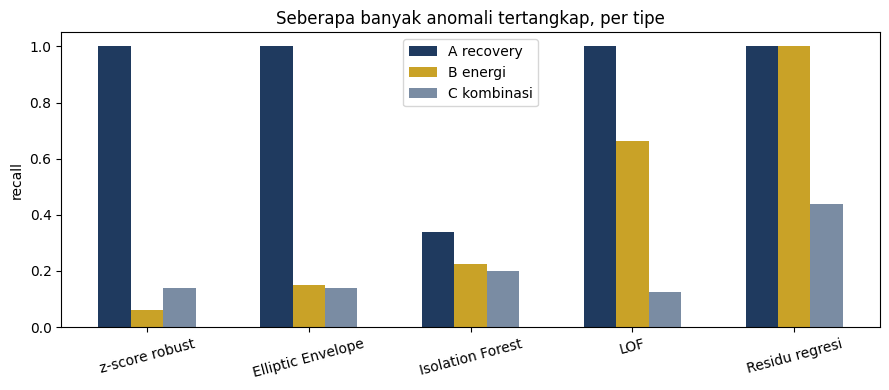

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4)); w = 0.2; xs = np.arange(len(hasil))
for k, (kol, wr) in enumerate([("recall_A", "#1F3A5F"), ("recall_B", "#C9A227"), ("recall_C", "#7A8CA3")]):
    ax.bar(xs + (k - 1) * w, hasil[kol], w, label={"recall_A": "A recovery", "recall_B": "B energi", "recall_C": "C kombinasi"}[kol], color=wr)
ax.set_xticks(xs); ax.set_xticklabels(hasil.index, rotation=15); ax.set_ylabel("recall"); ax.set_ylim(0, 1.05); ax.legend(); ax.set_title("Seberapa banyak anomali tertangkap, per tipe")
plt.tight_layout(); plt.show()

## 3. Pada data nyata: siapa yang ditandai, dan apakah metode sepakat?
Ambil 15 hari teratas dari tiap metode (≈ 5,5%). Hitung berapa metode yang menandai tiap hari.

In [ ]:
K = 15
skor = {n: f(X0) for n, f in METODE.items()}
tanda = pd.DataFrame({n: np.isin(np.arange(len(X0)), np.argsort(-s)[:K]) for n, s in skor.items()})
d["jml_metode"] = tanda.sum(axis=1)
d["rank_rata2"] = pd.DataFrame({n: pd.Series(s).rank(ascending=False) for n, s in skor.items()}).mean(axis=1)
konsensus = d[d.jml_metode >= 3].sort_values(["jml_metode", "rank_rata2"], ascending=[False, True])
konsensus = konsensus.assign(Tanggal=konsensus.Tanggal.dt.date)
print(konsensus[["Tanggal", "jml_metode", "Recovery_Persen", "Energi_per_t_Katoda_MWh", "Jam_Downtime", "Suhu_FSF_C", "O2_Enrichment_Persen"]].round(2).to_string(index=False))
print("\nKesepakatan antar metode (korelasi peringkat Spearman skor):")
print(pd.DataFrame(skor).corr(method="spearman").round(2))

   Tanggal  jml_metode  Recovery_Persen  Energi_per_t_Katoda_MWh  Jam_Downtime  Suhu_FSF_C  O2_Enrichment_Persen
2026-03-05           5            90.26                     1.54           0.0      1270.5                  59.7
2026-06-05           5            90.16                     1.47           0.0      1254.2                  61.9
2026-03-28           4            90.01                     1.49           4.0      1266.0                  62.2
2026-04-15           4            98.45                     1.71          14.0      1304.5                  58.1
2026-01-08           4            91.73                     1.38           0.0      1233.3                  62.5
2026-04-14           4            97.56                     1.59          14.0      1258.3                  60.0
2026-04-16           4            98.48                     1.65          14.0      1271.5                  58.1
2026-04-17           4            98.31                     1.70          14.0      1281.8      

## 4. Cek terhadap 5 hari recovery rendah yang sudah kita ketahui

In [ ]:
rendah = d.index[d.Recovery_Persen < 95]
print("Hari recovery < 95%:", [d.Tanggal[i].date().isoformat() for i in rendah])
print("Ditandai oleh berapa dari 5 metode:", dict(zip([d.Tanggal[i].date().isoformat() for i in rendah], d.jml_metode[rendah].tolist())))
print({n: int(tanda.loc[rendah, n].sum()) for n in METODE}, "<- jumlah dari 5 hari yang tertangkap per metode")

Hari recovery < 95%: ['2026-01-08', '2026-03-05', '2026-03-28', '2026-06-05', '2026-09-09']
Ditandai oleh berapa dari 5 metode: {'2026-01-08': 4, '2026-03-05': 5, '2026-03-28': 4, '2026-06-05': 5, '2026-09-09': 3}
{'z-score robust': 5, 'Elliptic Envelope': 4, 'Isolation Forest': 5, 'LOF': 5, 'Residu regresi': 2} <- jumlah dari 5 hari yang tertangkap per metode


**Mengapa residu regresi hanya menangkap 2 dari 5?** Karena `Cu_Slag_Persen` ikut menjelaskan recovery: pada 5 hari itu Cu di slag memang tinggi, jadi recovery rendahnya *konsisten* dengan sensor (anomali proses, bukan anomali pengukuran). Pada uji injeksi, model ini tampak unggul karena recovery diturunkan tanpa mengubah Cu slag (ketidakkonsistenan buatan). Kesimpulan: metode residu bagus untuk **mendeteksi data yang tidak konsisten antar sensor**, sedangkan metode jarak/isolasi bagus untuk **kondisi yang jarang terjadi**.

## 5. Anomali bukan berarti salah: beri konteks
Banyak hari ditandai karena *downtime panjang yang terjadwal* (kampanye refraktori April). Itu anomali statistik tetapi bukan masalah. Pisahkan:

In [ ]:
log = S["Downtime_Log"]; log["Tanggal"] = pd.to_datetime(log.Tanggal)
terjadwal = set(log.loc[log.Kategori == "Terjadwal", "Tanggal"])
d["terjadwal"] = d.Tanggal.isin(terjadwal)
kons = d[d.jml_metode >= 2]
print(f"Hari ditandai >= 2 metode: {len(kons)} | di antaranya hari downtime terjadwal: {int(kons.terjadwal.sum())} | tak terjadwal: {int((~kons.terjadwal).sum())}")
kons = kons.assign(Tanggal=kons.Tanggal.dt.date)
print(kons.loc[~kons.terjadwal, ["Tanggal", "jml_metode", "Recovery_Persen", "Energi_per_t_Katoda_MWh", "Jam_Downtime"]].round(2).to_string(index=False))

Hari ditandai >= 2 metode: 17 | di antaranya hari downtime terjadwal: 9 | tak terjadwal: 8
   Tanggal  jml_metode  Recovery_Persen  Energi_per_t_Katoda_MWh  Jam_Downtime
2026-01-08           4            91.73                     1.38           0.0
2026-03-05           5            90.26                     1.54           0.0
2026-03-07           2            97.84                     1.63          10.0
2026-03-28           4            90.01                     1.49           4.0
2026-04-27           2            97.89                     1.53           3.0
2026-05-01           2            98.84                     1.38           0.0
2026-06-05           5            90.16                     1.47           0.0
2026-09-09           3            92.26                     1.54           0.0


**Kesimpulan modul 8.**

*   Pada benchmark anomali suntikan, metode residu regresi terbaik (AUC 0,99), diikuti LOF (0,94). Z-score dan Isolation Forest lebih lemah pada pola kompleks.
*   Metode saling berbeda (korelasi peringkat dengan residu hanya 0,21–0,37), jadi gunakan konsensus. Lima hari recovery rendah ditandai 3–5 metode, dan 17 hari ditandai minimal dua metode.
*   Periode 14–19 April ikut terdeteksi karena downtime 14–16 jam per hari. Verifikasi hari-hari ini ke logbook.



